# Assignment 10: DBSCAN and Hierarchical Clustering

**Soumik Bhattacharyya**  
**MDE2026005**

## Part A: Dataset and Distance Preparation

### Task 1: Inspect the Dataset

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from scipy.cluster.hierarchy import dendrogram


In [4]:
# Load Iris dataset
data = load_iris()

X_original = data.data
y = data.target
feature_names = data.feature_names
class_names = data.target_names

# Dataset dimensions
n_records, n_features = X_original.shape
print("Number of records:", n_records)
print("Number of numerical features:", n_features)


Number of records: 150
Number of numerical features: 4


In [5]:

# Feature names, class names, and class counts
print("\\nFeature names:", feature_names)
print("Class names:", class_names)
print("\\nClass counts:")
print(pd.Series(y).map(dict(enumerate(class_names))).value_counts())


\nFeature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']
\nClass counts:
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [6]:
# Descriptive statistics
iris_df = pd.DataFrame(X_original, columns=feature_names)
print("\\nDescriptive statistics:")
display(iris_df.describe())


\nDescriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
# Check missing and infinite values
print("\\nMissing values per feature:")
print(iris_df.isna().sum())
print("\\nInfinite values per feature:")
print(pd.Series(np.isinf(X_original).sum(axis=0), index=feature_names))

\nMissing values per feature:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64
\nInfinite values per feature:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


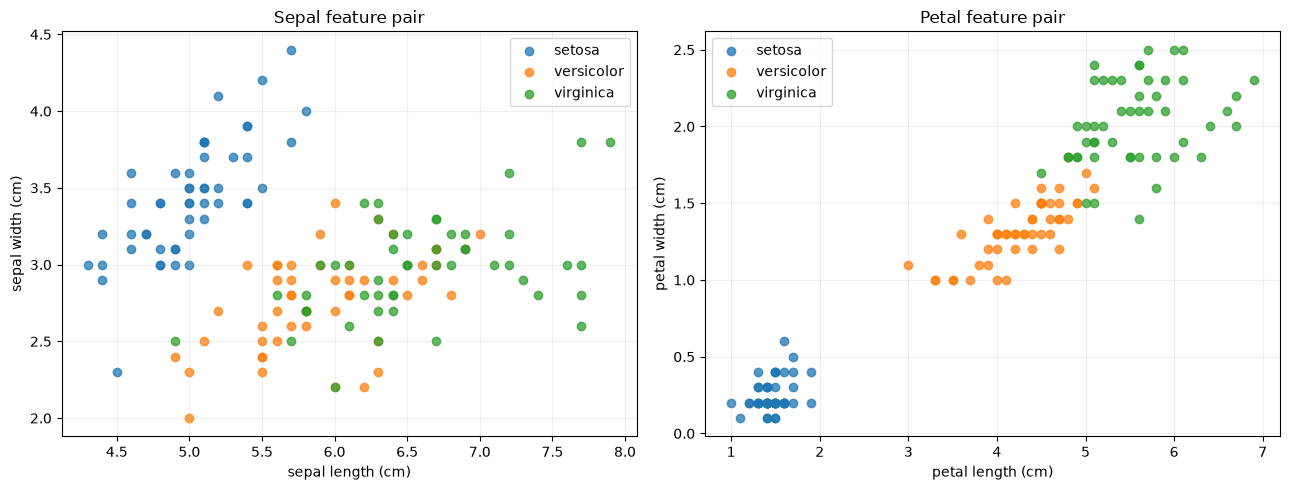

In [8]:
# At least two feature-pair scatter plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for class_id, class_name in enumerate(class_names):
    mask = y == class_id
    axes[0].scatter(X_original[mask, 0], X_original[mask, 1],
                    label=class_name, alpha=0.75)
    axes[1].scatter(X_original[mask, 2], X_original[mask, 3],
                    label=class_name, alpha=0.75)

axes[0].set_xlabel(feature_names[0])
axes[0].set_ylabel(feature_names[1])
axes[0].set_title("Sepal feature pair")
axes[1].set_xlabel(feature_names[2])
axes[1].set_ylabel(feature_names[3])
axes[1].set_title("Petal feature pair")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Iris is useful for clustering because it contains a small set of numerical measurements and known species labels that can be reserved for post-clustering evaluation. Its limitation is that some species overlap in feature space, so the natural groups are not perfectly separated.

Feature scaling is important because distance-based algorithms are sensitive to differences in feature magnitudes. Without scaling, features with larger numerical ranges can dominate distance calculations. Standardization gives each feature a comparable scale.

Species labels must remain separate during clustering because using them during fitting would introduce prior class information and make the clustering evaluation biased. They are used only after clustering to evaluate agreement with the known classes.

### Task 2: Distance Calculation

In [9]:
def euclidean_distance(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return float(np.sqrt(np.sum((x - y) ** 2)))


def manhattan_distance(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return float(np.sum(np.abs(x - y)))


# Test on at least three observation pairs using the original measurements
test_pairs = [(0, 1), (0, 50), (100, 149)]
distance_results = []
for i, j in test_pairs:
    distance_results.append({
        "Observation pair": f"({i}, {j})",
        "Euclidean distance": euclidean_distance(X_original[i], X_original[j]),
        "Manhattan distance": manhattan_distance(X_original[i], X_original[j])
    })

print(pd.DataFrame(distance_results).to_string(index=False))


Observation pair  Euclidean distance  Manhattan distance
          (0, 1)            0.538516                 0.7
         (0, 50)            4.003748                 6.7
      (100, 149)            1.244990                 2.3


Distance metric choice changes which observations are considered close and therefore can change neighbourhood membership and cluster structure. Euclidean distance measures straight-line distance, while Manhattan distance sums coordinate-wise absolute differences. Euclidean distance is used as the primary metric in the main experiments.

### Task 3: Construct and Inspect the Distance Matrix

In [10]:
# Standardize numerical features for the main experiments.
# Species labels are kept separate and are not used during clustering.
scaler = StandardScaler()
X = scaler.fit_transform(X_original)

def pairwise_distance_matrix(X):
    X = np.asarray(X, dtype=float)
    n = len(X)
    distances = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            distance = euclidean_distance(X[i], X[j])
            distances[i, j] = distance
            distances[j, i] = distance
    return distances


# Display the pairwise distance matrix for the first 10 observations
distance_matrix_10 = pairwise_distance_matrix(X[:10])
distance_df = pd.DataFrame(
    distance_matrix_10,
    index=range(10),
    columns=range(10)
)
display(distance_df)

print("All diagonal entries are zero:",
      np.allclose(np.diag(distance_matrix_10), 0))
print("Matrix is symmetric:",
      np.allclose(distance_matrix_10, distance_matrix_10.T))


,0,1,2,3,4,5,6,7,8,9
0,0.000000,1.176219,0.845607,1.103685,0.260139,1.038444,0.661331,0.266276,1.620821,0.962877
1,1.176219,0.000000,0.523373,0.434000,1.386485,2.181206,0.998654,0.930463,0.648099,0.271197
2,0.845607,0.523373,0.000000,0.283891,0.991572,1.853897,0.497194,0.597511,0.782483,0.376784
3,1.103685,0.434000,0.283891,0.000000,1.250160,2.100774,0.705317,0.843695,0.523373,0.386603
4,0.260139,1.386485,0.991572,1.250160,0.000000,0.900113,0.681319,0.463889,1.767789,1.166192
5,1.038444,2.181206,1.853897,2.100774,0.900113,0.000000,1.520129,1.281367,2.620230,1.981742
6,0.661331,0.998654,0.497194,0.705317,0.681319,1.520129,0.000000,0.505434,1.183561,0.825584
7,0.266276,0.930463,0.597511,0.843695,0.463889,1.281367,0.505434,0.000000,1.362547,0.713389
8,1.620821,0.648099,0.782483,0.523373,1.767789,2.620230,1.183561,1.362547,0.000000,0.774313
9,0.962877,0.271197,0.376784,0.386603,1.166192,1.981742,0.825584,0.713389,0.774313,0.000000


All diagonal entries are zero: True
Matrix is symmetric: True


A full \(N \\times N\) distance matrix requires \(O(N^2)\) storage because it stores a distance for every pair of observations. The DBSCAN implementation below calculates distances during neighbourhood queries. The hierarchical implementation calculates and updates cluster distances as needed.

## Part B: DBSCAN — Density-Based Clustering

### Task 4: Find Epsilon-Neighbourhoods

In [11]:
def region_query(X, point_index, eps):
    neighbours = []
    for index in range(len(X)):
        if euclidean_distance(X[point_index], X[index]) <= eps:
            neighbours.append(index)
    return neighbours


# Inspect epsilon-neighbourhoods for at least five observations
EPS_FOR_NEIGHBOURHOOD = 0.8
MIN_PTS_FOR_NEIGHBOURHOOD = 5

neighbourhood_rows = []
for point_index in range(5):
    neighbours = region_query(X, point_index, EPS_FOR_NEIGHBOURHOOD)
    neighbourhood_rows.append({
        "Point index": point_index,
        "Neighbourhood indices": neighbours,
        "Neighbourhood count": len(neighbours),
        "Self included": point_index in neighbours
    })

display(pd.DataFrame(neighbourhood_rows))


,Point index,Neighbourhood indices,Neighbourhood count,Self included
0,0,"[0, 4, 6, 7, 10, 11, 17, 19, 20, 21, 22, 23, 2...",27,True
1,1,"[1, 2, 3, 8, 9, 12, 13, 25, 29, 30, 34, 35, 38...",17,True
2,2,"[1, 2, 3, 6, 7, 8, 9, 11, 12, 13, 23, 24, 25, ...",26,True
3,3,"[1, 2, 3, 6, 8, 9, 11, 12, 13, 24, 25, 29, 30,...",20,True
4,4,"[0, 4, 6, 7, 10, 11, 17, 19, 20, 21, 22, 24, 2...",25,True


The point itself is included in its epsilon-neighbourhood because its distance from itself is zero. Increasing \(eps\) can only maintain or increase neighbourhood sizes, since more observations may fall within the larger radius.

### Task 5: Identify Core, Border, and Noise Points

In [12]:
def classify_points(X, eps, min_pts):
    neighbourhoods = [
        region_query(X, i, eps) for i in range(len(X))
    ]

    core_indices = {
        i for i, neighbours in enumerate(neighbourhoods)
        if len(neighbours) >= min_pts
    }

    border_indices = set()
    for core_index in core_indices:
        for neighbour in neighbourhoods[core_index]:
            if neighbour not in core_indices:
                border_indices.add(neighbour)

    noise_indices = set(range(len(X))) - core_indices - border_indices
    return neighbourhoods, core_indices, border_indices, noise_indices


EPS_CLASSIFICATION = 0.8
MIN_PTS_CLASSIFICATION = 5

neighbourhoods, core_indices, border_indices, noise_indices = classify_points(
    X, EPS_CLASSIFICATION, MIN_PTS_CLASSIFICATION
)

point_type_rows = []
for i, neighbours in enumerate(neighbourhoods):
    if i in core_indices:
        point_type = "Core"
    elif i in border_indices:
        point_type = "Border"
    else:
        point_type = "Noise"

    point_type_rows.append({
        "Point index": i,
        "Neighbourhood count": len(neighbours),
        "Point type": point_type
    })

point_type_df = pd.DataFrame(point_type_rows)
display(point_type_df)
print("Core points:", len(core_indices))
print("Border points:", len(border_indices))
print("Noise points:", len(noise_indices))


,Point index,Neighbourhood count,Point type
0,0,27,Core
1,1,17,Core
2,2,26,Core
3,3,20,Core
4,4,25,Core
...,...,...,...
145,145,18,Core
146,146,10,Core
147,147,23,Core
148,148,7,Core


Core points: 138
Border points: 8
Noise points: 4


A border point does not have enough neighbours to satisfy the core-point condition, but it lies within the epsilon-neighbourhood of a core point and can be assigned to that core point's cluster. A noise point is not density-reachable from any core point and remains unassigned.

### Task 6: Implement DBSCAN Cluster Expansion

In [13]:
def dbscan_from_scratch(X, eps, min_pts):
    n = len(X)
    labels = np.full(n, -1, dtype=int)
    visited = np.zeros(n, dtype=bool)
    core_indices = set()
    cluster_id = 0

    for point in range(n):
        if visited[point]:
            continue

        visited[point] = True
        neighbours = region_query(X, point, eps)

        # A non-core point remains noise unless later reached by a cluster.
        if len(neighbours) < min_pts:
            continue

        core_indices.add(point)
        labels[point] = cluster_id
        seeds = list(neighbours)
        seed_position = 0

        while seed_position < len(seeds):
            candidate = seeds[seed_position]
            seed_position += 1

            if not visited[candidate]:
                visited[candidate] = True
                candidate_neighbours = region_query(X, candidate, eps)

                if len(candidate_neighbours) >= min_pts:
                    core_indices.add(candidate)
                    for neighbour in candidate_neighbours:
                        if neighbour not in seeds:
                            seeds.append(neighbour)

            # Assign unassigned points, including border points, to this cluster.
            if labels[candidate] == -1:
                labels[candidate] = cluster_id

        cluster_id += 1

    noise_indices = set(np.where(labels == -1)[0])
    border_indices = set(np.where(labels >= 0)[0]) - core_indices

    return labels, core_indices, border_indices, noise_indices, cluster_id




### Task 7: Run and Inspect DBSCAN

DBSCAN parameters: eps = 0.8 , MinPts = 5
Number of clusters: 2
Number of noise points: 4
\nCluster sizes:


,Size
0,49
1,97


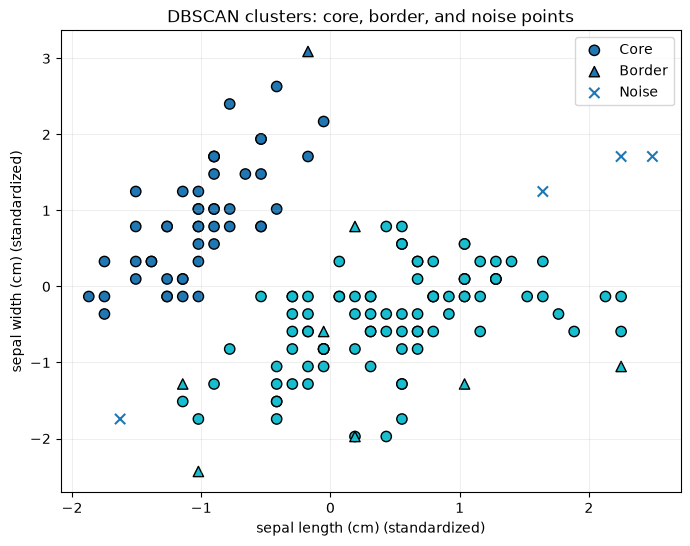

In [14]:
EPS_MAIN = 0.8
MIN_PTS_MAIN = 5

dbscan_labels, dbscan_core, dbscan_border, dbscan_noise, dbscan_cluster_count = (
    dbscan_from_scratch(X, EPS_MAIN, MIN_PTS_MAIN)
)

print("DBSCAN parameters: eps =", EPS_MAIN, ", MinPts =", MIN_PTS_MAIN)
print("Number of clusters:", dbscan_cluster_count)
print("Number of noise points:", len(dbscan_noise))

dbscan_cluster_sizes = (
    pd.Series(dbscan_labels[dbscan_labels != -1])
    .value_counts().sort_index()
)
print("\\nCluster sizes:")
display(dbscan_cluster_sizes.rename("Size").to_frame())

dbscan_type = np.array([
    "Core" if i in dbscan_core else
    "Border" if i in dbscan_border else
    "Noise"
    for i in range(len(X))
])

# Plot using two standardized features
marker_map = {"Core": "o", "Border": "^", "Noise": "x"}
fig, ax = plt.subplots(figsize=(8, 6))
for point_type, marker in marker_map.items():
    mask = dbscan_type == point_type
    ax.scatter(X[mask, 0], X[mask, 1],
               c=dbscan_labels[mask], cmap="tab10",
               marker=marker, s=55, label=point_type,
               edgecolors="black" if point_type != "Noise" else None)
ax.set_xlabel(feature_names[0] + " (standardized)")
ax.set_ylabel(feature_names[1] + " (standardized)")
ax.set_title("DBSCAN clusters: core, border, and noise points")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


DBSCAN does not require the number of clusters in advance. It forms clusters by expanding from core points whose neighbourhoods satisfy the density requirement.

### Task 8: Effect of Epsilon (eps)

,eps,Cluster count,Noise count,Cluster sizes
0,0.3,3,120,"[13, 12, 5]"
1,0.4,6,66,"[39, 9, 7, 18, 4, 7]"
2,0.5,2,34,"[45, 71]"
3,0.6,2,26,"[46, 78]"
4,0.8,2,4,"[49, 97]"
5,1.0,2,3,"[49, 98]"
6,1.2,2,1,"[49, 100]"


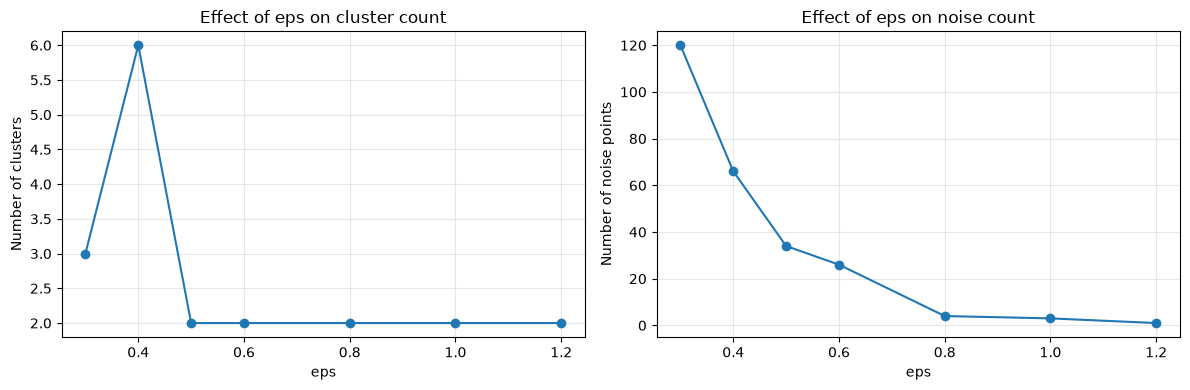

In [15]:
EPS_VALUES = [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]
MIN_PTS_EPS_STUDY = 5

eps_experiment_rows = []
for eps in EPS_VALUES:
    labels, core, border, noise, cluster_count = dbscan_from_scratch(
        X, eps, MIN_PTS_EPS_STUDY
    )
    sizes = pd.Series(labels[labels != -1]).value_counts().sort_index().tolist()
    eps_experiment_rows.append({
        "eps": eps,
        "Cluster count": cluster_count,
        "Noise count": len(noise),
        "Cluster sizes": sizes
    })

eps_results = pd.DataFrame(eps_experiment_rows)
display(eps_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(eps_results["eps"], eps_results["Cluster count"], marker="o")
axes[0].set_xlabel("eps")
axes[0].set_ylabel("Number of clusters")
axes[0].set_title("Effect of eps on cluster count")
axes[1].plot(eps_results["eps"], eps_results["Noise count"], marker="o")
axes[1].set_xlabel("eps")
axes[1].set_ylabel("Number of noise points")
axes[1].set_title("Effect of eps on noise count")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


If \(eps\) is too small, many observations fail the density requirement and may be labelled as noise; clusters may also fragment. If \(eps\) is too large, nearby groups may merge into a single cluster and fewer observations are labelled as noise. A useful value should balance cluster formation and noise without merging clearly distinct groups.

Based on the experiments, eps = 0.8 is selected for the main DBSCAN experiment with MinPts = 5. It produces two clusters with only four noise points. Smaller values, such as 0.3 and 0.4, classify many observations as noise, while increasing eps further provides little improvement in noise reduction. Therefore, eps = 0.8 provides a reasonable balance between cluster formation and noise identification for this dataset.

### Task 9: Effect of MinPts

,MinPts,Cluster count,Noise count,Cluster sizes
0,3,2,4,"[49, 97]"
1,4,2,4,"[49, 97]"
2,5,2,4,"[49, 97]"
3,6,2,4,"[49, 97]"
4,8,2,8,"[48, 94]"
5,10,2,8,"[48, 94]"


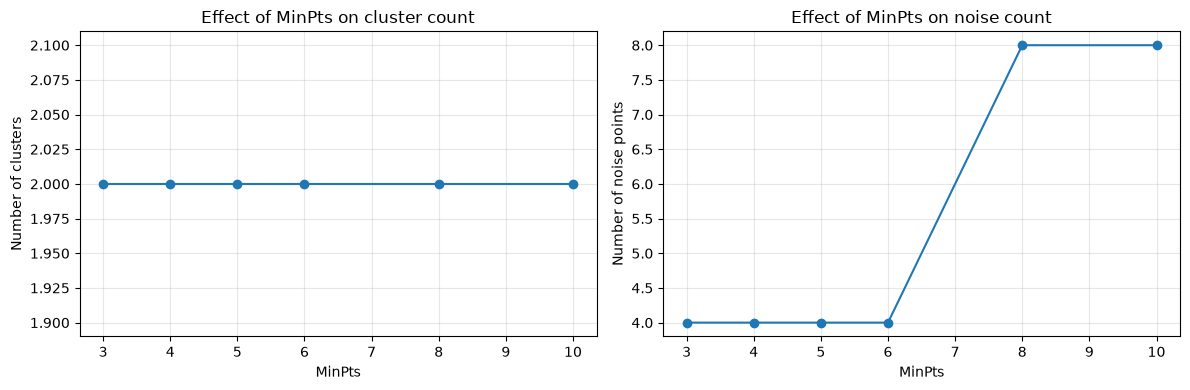

In [16]:
MIN_PTS_VALUES = [3, 4, 5, 6, 8, 10]
EPS_MINPTS_STUDY = EPS_MAIN

minpts_experiment_rows = []
for min_pts in MIN_PTS_VALUES:
    labels, core, border, noise, cluster_count = dbscan_from_scratch(
        X, EPS_MINPTS_STUDY, min_pts
    )
    sizes = pd.Series(labels[labels != -1]).value_counts().sort_index().tolist()
    minpts_experiment_rows.append({
        "MinPts": min_pts,
        "Cluster count": cluster_count,
        "Noise count": len(noise),
        "Cluster sizes": sizes
    })

minpts_results = pd.DataFrame(minpts_experiment_rows)
display(minpts_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(minpts_results["MinPts"], minpts_results["Cluster count"], marker="o")
axes[0].set_xlabel("MinPts")
axes[0].set_ylabel("Number of clusters")
axes[0].set_title("Effect of MinPts on cluster count")
axes[1].plot(minpts_results["MinPts"], minpts_results["Noise count"], marker="o")
axes[1].set_xlabel("MinPts")
axes[1].set_ylabel("Number of noise points")
axes[1].set_title("Effect of MinPts on noise count")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Increasing MinPts makes the core-point condition stricter, requiring a denser neighbourhood. This can reject sparse regions as noise and reduce the number of clusters, while smaller values can retain weaker-density regions but may also create less robust clusters.

### Task 10: Parameter Selection and k-Distance Plot

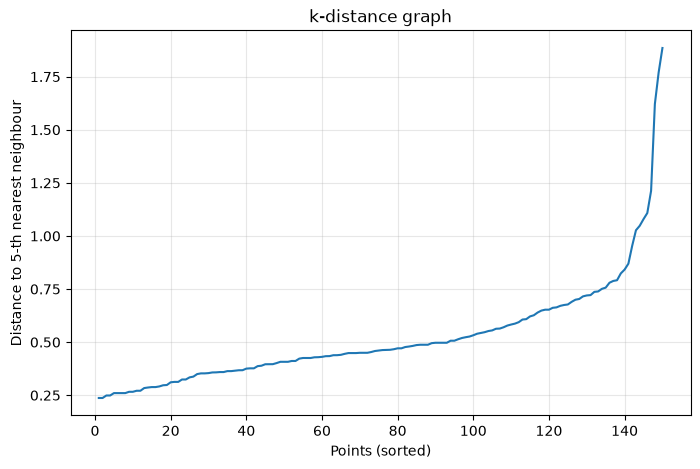

{'eps': 0.8, 'cluster_count': 2, 'noise_count': 4, 'cluster_sizes': {1: 97, 0: 49}}
{'eps': 1.0, 'cluster_count': 2, 'noise_count': 3, 'cluster_sizes': {1: 98, 0: 49}}


In [17]:
def k_distance_values(X, min_pts):
    values = []
    for i in range(len(X)):
        distances = sorted(
            euclidean_distance(X[i], X[j])
            for j in range(len(X))
        )
        # Self-distance is zero and is included in MinPts.
        values.append(distances[min_pts - 1])
    return np.sort(np.asarray(values))


K_FOR_DISTANCE = 5
k_distances = k_distance_values(X, K_FOR_DISTANCE)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances)
plt.xlabel("Points (sorted)")
plt.ylabel(f"Distance to {K_FOR_DISTANCE}-th nearest neighbour")
plt.title("k-distance graph")
plt.grid(alpha=0.3)
plt.show()

# Compare an eps selected from visual inspection with an alternative.
# Update EPS_FROM_ELBOW after inspecting the graph.
EPS_FROM_ELBOW = 0.8
EPS_ALTERNATIVE = 1.0

for candidate_eps in [EPS_FROM_ELBOW, EPS_ALTERNATIVE]:
    labels, core, border, noise, cluster_count = dbscan_from_scratch(
        X, candidate_eps, K_FOR_DISTANCE
    )
    print({
        "eps": candidate_eps,
        "cluster_count": cluster_count,
        "noise_count": len(noise),
        "cluster_sizes": pd.Series(labels[labels != -1]).value_counts().to_dict()
    })


The elbow is a heuristic because it depends on the shape and density distribution of the data. It may be difficult to identify when clusters have different densities or when the sorted distances change gradually rather than showing a clear bend.

### Task 11: DBSCAN Strengths and Limitations

DBSCAN can discover irregularly shaped clusters because membership is based on density reachability rather than distance to a centroid. It can identify noise and outliers as observations that are not density-reachable from core points. Its results are sensitive to \(eps\) and MinPts. A single global \(eps\) may fail when clusters have substantially different densities: a value suitable for a sparse cluster may merge dense clusters, while a value suitable for dense clusters may reject sparse ones. In high dimensions, distances can become less discriminative and neighbourhood density becomes harder to estimate reliably.

## Part C: Hierarchical Clustering

### Task 12: Understand Agglomerative Clustering

Agglomerative clustering is a bottom-up process. It begins with \(N\) singleton clusters and repeatedly merges the closest pair according to a selected linkage criterion. It continues until one cluster remains or a stopping condition, such as a requested cluster count or distance threshold, is reached. Divisive clustering follows the opposite, top-down direction: it begins with one cluster and repeatedly splits it.

### Task 13: Implement Linkage Criteria

In [18]:
def single_linkage(cluster_a, cluster_b, X):
    return min(
        euclidean_distance(X[i], X[j])
        for i in cluster_a for j in cluster_b
    )


def complete_linkage(cluster_a, cluster_b, X):
    return max(
        euclidean_distance(X[i], X[j])
        for i in cluster_a for j in cluster_b
    )


def average_linkage(cluster_a, cluster_b, X):
    distances = [
        euclidean_distance(X[i], X[j])
        for i in cluster_a for j in cluster_b
    ]
    return float(np.mean(distances))


def ward_merge_cost(cluster_a, cluster_b, X):
    points_a = X[list(cluster_a)]
    points_b = X[list(cluster_b)]
    mean_a = np.mean(points_a, axis=0)
    mean_b = np.mean(points_b, axis=0)
    factor = len(points_a) * len(points_b) / (
        len(points_a) + len(points_b)
    )
    return float(factor * np.sum((mean_a - mean_b) ** 2))


# Test all three linkage functions and Ward merge cost on a small dataset
X_small = np.array([
    [0.0, 0.0],
    [1.0, 0.0],
    [4.0, 0.0],
    [5.0, 0.0]
])
cluster_a = {0, 1}
cluster_b = {2, 3}

print("Single linkage:", single_linkage(cluster_a, cluster_b, X_small))
print("Complete linkage:", complete_linkage(cluster_a, cluster_b, X_small))
print("Average linkage:", average_linkage(cluster_a, cluster_b, X_small))
print("Ward merge cost:", ward_merge_cost(cluster_a, cluster_b, X_small))


Single linkage: 3.0
Complete linkage: 5.0
Average linkage: 4.0
Ward merge cost: 16.0


Single linkage uses the minimum cross-cluster pairwise distance and can cause chaining, where clusters are joined through a sequence of nearby points. Complete linkage uses the maximum cross-cluster distance and therefore favours compact clusters. Average linkage uses the mean of all cross-cluster pairwise distances, balancing the influence of the closest and farthest pairs. Ward's merge cost is the increase in within-cluster sum of squared errors caused by merging two clusters; it is defined for Euclidean feature data.

### Task 14: Implement Agglomerative Hierarchical Clustering

In [20]:
def agglomerative_clustering(X, linkage="average", n_clusters=3):
    linkage_functions = {
        "single": single_linkage,
        "complete": complete_linkage,
        "average": average_linkage
    }
    if linkage not in linkage_functions:
        raise ValueError("Choose single, complete, or average linkage.")
    if not 1 <= n_clusters <= len(X):
        raise ValueError("n_clusters must be between 1 and the number of observations.")

    distance_function = linkage_functions[linkage]
    clusters = [{i} for i in range(len(X))]
    merge_history = []

    while len(clusters) > 1:
        best_distance = float("inf")
        best_pair = None

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                distance = distance_function(clusters[i], clusters[j], X)
                if distance < best_distance:
                    best_distance = distance
                    best_pair = (i, j)

        i, j = best_pair
        left_cluster = clusters[i].copy()
        right_cluster = clusters[j].copy()
        merged_cluster = left_cluster | right_cluster

        merge_history.append({
            "left_cluster": sorted(left_cluster),
            "right_cluster": sorted(right_cluster),
            "merged_cluster": sorted(merged_cluster),
            "distance": best_distance,
            "size": len(merged_cluster)
        })

        clusters[i] = merged_cluster
        del clusters[j]

        if len(clusters) == n_clusters:
            # Continue to build full merge history for dendrogram and threshold cuts.
            pass

    # Reconstruct the requested k-cluster partition from the first N-k merges.
    active_clusters = [{i} for i in range(len(X))]
    for merge in merge_history[:len(X) - n_clusters]:
        left = set(merge["left_cluster"])
        right = set(merge["right_cluster"])
        merged = left | right
        active_clusters = [
            cluster for cluster in active_clusters
            if cluster != left and cluster != right
        ]
        active_clusters.append(merged)

    labels = np.empty(len(X), dtype=int)
    for cluster_id, cluster in enumerate(active_clusters):
        for observation in cluster:
            labels[observation] = cluster_id

    return labels, active_clusters, merge_history




### Task 15: Run Different Linkage Methods

,Linkage,Cluster sizes,Labels
0,single,"[1, 49, 100]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
1,complete,"[24, 49, 77]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
2,average,"[3, 97, 50]","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ..."


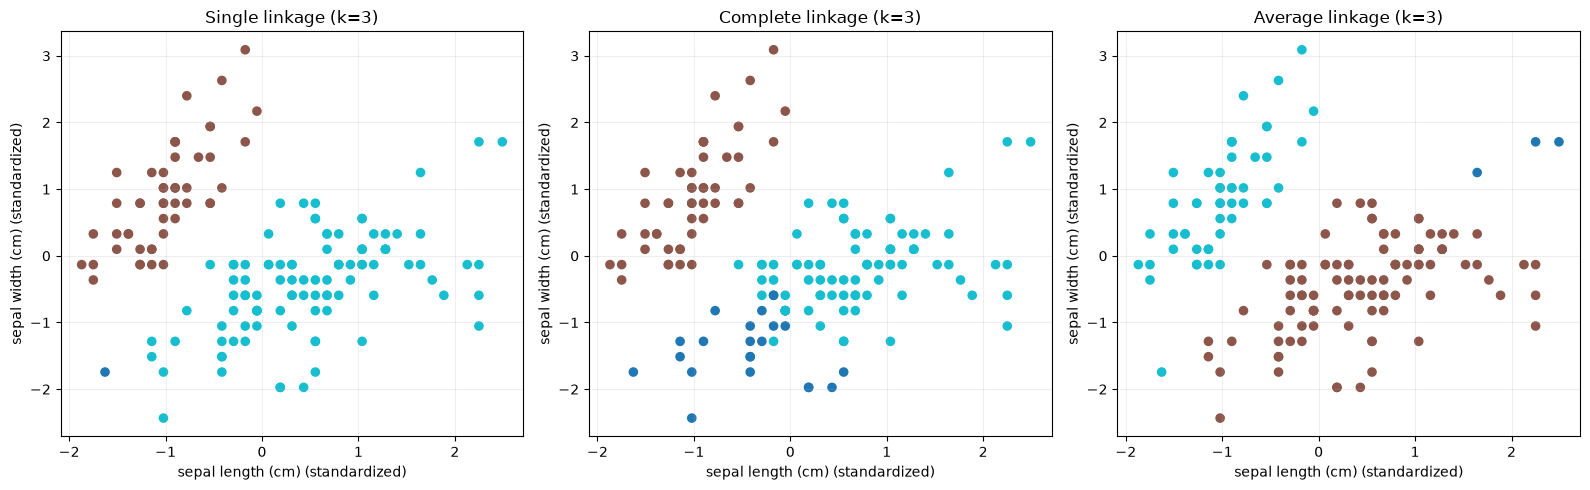

In [21]:
LINKAGE_METHODS = ["single", "complete", "average"]
K_HIERARCHICAL = 3

hierarchical_results = {}
hierarchical_rows = []

for method in LINKAGE_METHODS:
    labels, clusters, history = agglomerative_clustering(
        X, linkage=method, n_clusters=K_HIERARCHICAL
    )
    hierarchical_results[method] = {
        "labels": labels,
        "clusters": clusters,
        "history": history
    }
    hierarchical_rows.append({
        "Linkage": method,
        "Cluster sizes": [len(cluster) for cluster in clusters],
        "Labels": labels.tolist()
    })

display(pd.DataFrame(hierarchical_rows))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, method in zip(axes, LINKAGE_METHODS):
    labels = hierarchical_results[method]["labels"]
    scatter = ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=35)
    ax.set_title(f"{method.capitalize()} linkage (k=3)")
    ax.set_xlabel(feature_names[0] + " (standardized)")
    ax.set_ylabel(feature_names[1] + " (standardized)")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Linkage choice changes the distance between clusters and therefore changes the order in which merges occur. Single linkage can connect elongated or chained groups, complete linkage tends to produce compact groups, and average linkage uses all cross-cluster pairwise distances and often gives an intermediate result.

### Task 16: Dendrogram Construction and Interpretation

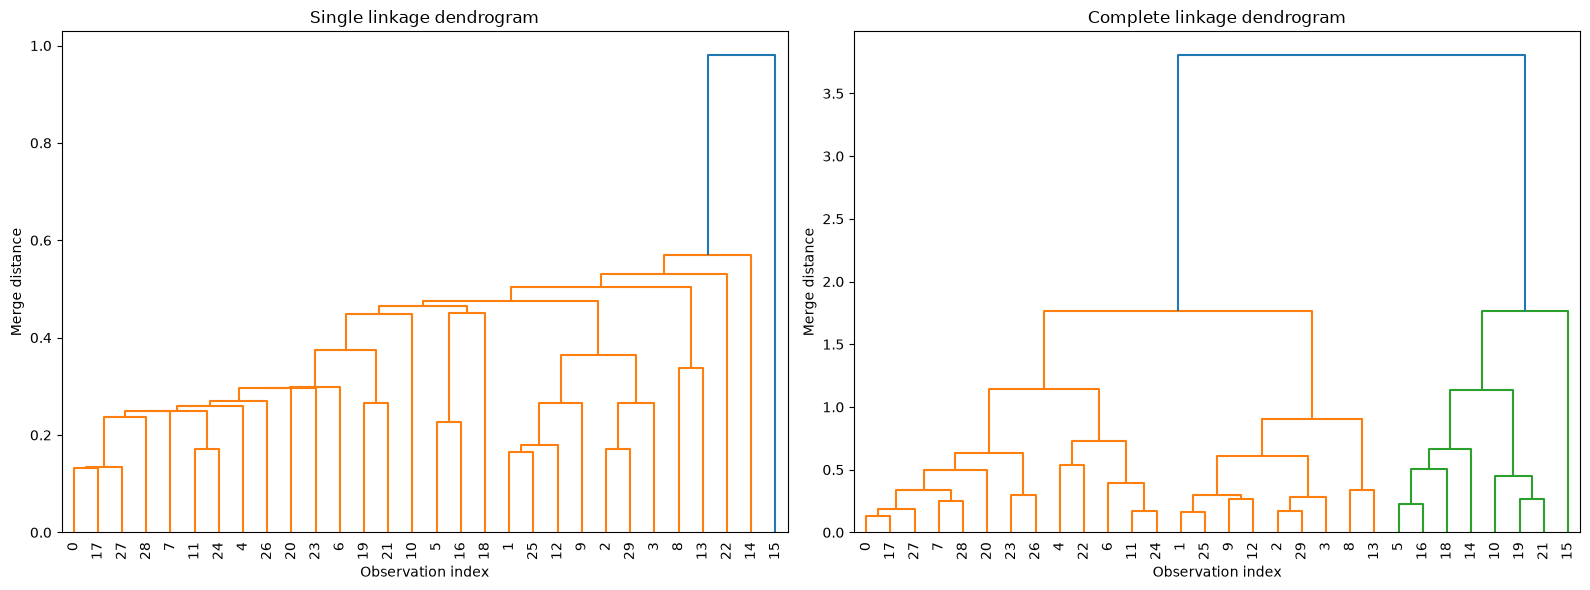

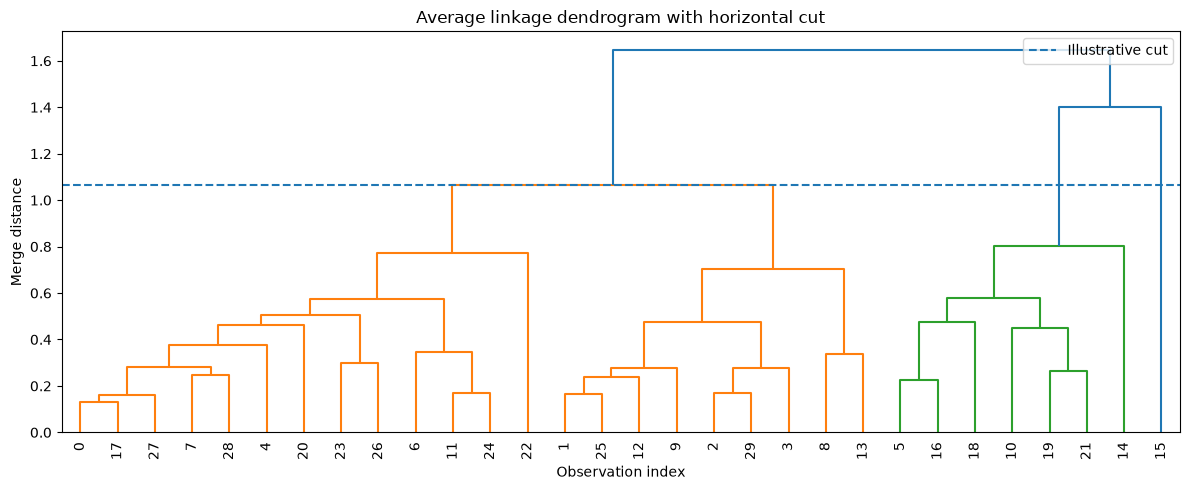

In [22]:
def scipy_linkage_matrix_from_history(merge_history, n_observations):
    cluster_to_id = {frozenset([i]): i for i in range(n_observations)}
    linkage_rows = []

    for step, merge in enumerate(merge_history):
        left = frozenset(merge["left_cluster"])
        right = frozenset(merge["right_cluster"])
        left_id = cluster_to_id[left]
        right_id = cluster_to_id[right]
        merged = left | right
        merged_id = n_observations + step

        linkage_rows.append([
            left_id,
            right_id,
            merge["distance"],
            len(merged)
        ])
        cluster_to_id[merged] = merged_id

    return np.asarray(linkage_rows, dtype=float)


# Build full merge histories for a manageable subset.
DENDROGRAM_SIZE = 30
X_dendrogram = X[:DENDROGRAM_SIZE]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["single", "complete"]):
    _, _, history = agglomerative_clustering(
        X_dendrogram, linkage=method, n_clusters=1
    )
    linkage_matrix = scipy_linkage_matrix_from_history(
        history, len(X_dendrogram)
    )
    dendrogram(
        linkage_matrix,
        labels=[str(i) for i in range(DENDROGRAM_SIZE)],
        ax=ax,
        leaf_rotation=90
    )
    ax.set_title(f"{method.capitalize()} linkage dendrogram")
    ax.set_xlabel("Observation index")
    ax.set_ylabel("Merge distance")

plt.tight_layout()
plt.show()

# Example horizontal cut for a selected number of clusters on the subset
_, _, subset_history = agglomerative_clustering(
    X_dendrogram, linkage="average", n_clusters=1
)
subset_linkage_matrix = scipy_linkage_matrix_from_history(
    subset_history, len(X_dendrogram)
)
plt.figure(figsize=(12, 5))
dendrogram(
    subset_linkage_matrix,
    labels=[str(i) for i in range(DENDROGRAM_SIZE)],
    leaf_rotation=90
)
selected_cut = subset_linkage_matrix[-3, 2] if len(subset_linkage_matrix) >= 3 else 0
plt.axhline(selected_cut, linestyle="--", label="Illustrative cut")
plt.xlabel("Observation index")
plt.ylabel("Merge distance")
plt.title("Average linkage dendrogram with horizontal cut")
plt.legend()
plt.tight_layout()
plt.show()


Large vertical gaps in a dendrogram indicate merge steps that join clusters at substantially different distances; a horizontal cut within such a gap can be a reasonable candidate partition. Plotting every observation as a leaf can make labels and branches crowded, so a manageable subset is useful for interpretation.

A horizontal cut through a dendrogram determines the number of clusters by separating branches below the selected merge distance. The number of disconnected branches intersected by the cut gives the resulting cluster count. A cut at a lower distance generally produces more clusters, while a higher cut produces fewer clusters.

### Task 17: Effect of Linkage and Number of Clusters

,Linkage,k,Cluster sizes,Silhouette,ARI,NMI
0,single,2,"[100, 50]",0.581750,0.568116,0.733680
1,single,3,"[1, 49, 100]",0.504646,0.558371,0.720118
2,single,4,"[1, 49, 97, 3]",0.406746,0.552203,0.700554
3,single,5,"[1, 1, 2, 49, 97]",0.342409,0.551796,0.695786
4,complete,2,"[77, 73]",0.440812,0.410154,0.457793
5,complete,3,"[24, 49, 77]",0.449618,0.572631,0.653048
6,complete,4,"[66, 11, 24, 49]",0.410607,0.533199,0.626676
7,complete,5,"[7, 42, 66, 11, 24]",0.352063,0.462522,0.592326
8,average,2,"[50, 100]",0.581750,0.568116,0.733680
9,average,3,"[3, 97, 50]",0.480267,0.562136,0.713099


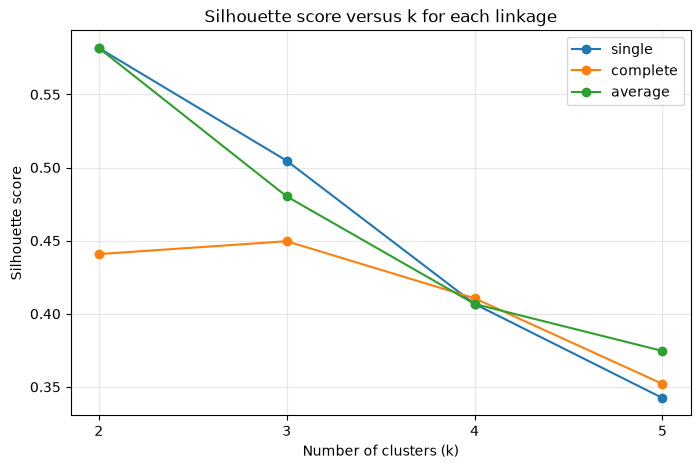

In [23]:
K_VALUES = [2, 3, 4, 5]
linkage_k_rows = []

for method in LINKAGE_METHODS:
    for k in K_VALUES:
        labels, clusters, history = agglomerative_clustering(
            X, linkage=method, n_clusters=k
        )
        silhouette = silhouette_score(X, labels)
        ari = adjusted_rand_score(y, labels)
        nmi = normalized_mutual_info_score(y, labels)

        linkage_k_rows.append({
            "Linkage": method,
            "k": k,
            "Cluster sizes": [len(cluster) for cluster in clusters],
            "Silhouette": silhouette,
            "ARI": ari,
            "NMI": nmi
        })

linkage_k_results = pd.DataFrame(linkage_k_rows)
display(linkage_k_results)

plt.figure(figsize=(8, 5))
for method in LINKAGE_METHODS:
    subset = linkage_k_results[linkage_k_results["Linkage"] == method]
    plt.plot(subset["k"], subset["Silhouette"], marker="o", label=method)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score versus k for each linkage")
plt.xticks(K_VALUES)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


For k = 3, complete linkage achieves the highest ARI (0.572631), while single linkage achieves the highest silhouette score (0.504646) among the three-linkage k = 3 configurations.

For k = 2, single and average linkage achieve the highest silhouette score (0.581750). Therefore, the preferred partition depends on whether internal cluster separation or agreement with known species labels is prioritized. Complete linkage with k = 3 provides the strongest external agreement among the tested k = 3 configurations.

No linkage method is universally best because each encodes a different definition of cluster proximity. The preferred partition depends on the data's geometry, noise, density, and the evaluation criteria relevant to the application.

### Task 18: Effect of Distance Threshold

,Distance threshold,Cluster count,Cluster sizes
0,0.423453,75,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
1,0.661457,38,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 4, 2, ..."
2,1.008351,16,"[1, 1, 1, 4, 2, 17, 4, 7, 4, 7, 21, 23, 28, 4,..."


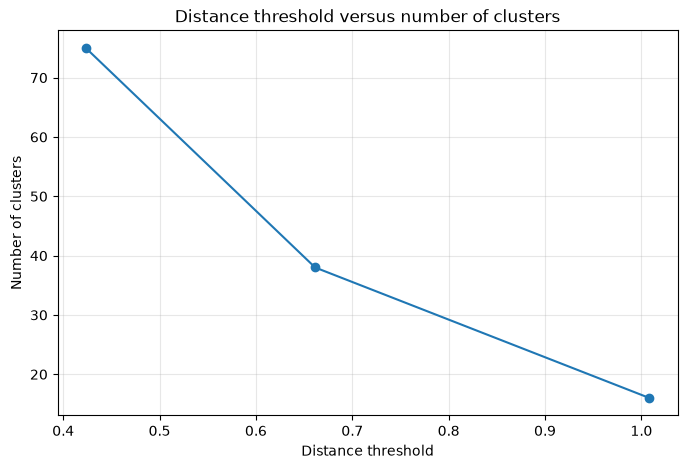

In [24]:
def labels_from_merge_threshold(merge_history, n_observations, threshold):
    clusters = [{i} for i in range(n_observations)]

    for merge in merge_history:
        if merge["distance"] > threshold:
            break
        left = set(merge["left_cluster"])
        right = set(merge["right_cluster"])
        merged = left | right
        clusters = [
            cluster for cluster in clusters
            if cluster != left and cluster != right
        ]
        clusters.append(merged)

    labels = np.empty(n_observations, dtype=int)
    for cluster_id, cluster in enumerate(clusters):
        for observation in cluster:
            labels[observation] = cluster_id

    return labels, clusters


# Use average-linkage merge history and select three thresholds from its distances.
_, _, average_full_history = agglomerative_clustering(
    X, linkage="average", n_clusters=1
)
merge_distances = np.array([
    merge["distance"] for merge in average_full_history
])
threshold_values = np.quantile(merge_distances, [0.50, 0.75, 0.90])

threshold_rows = []
for threshold in threshold_values:
    labels, clusters = labels_from_merge_threshold(
        average_full_history, len(X), float(threshold)
    )
    threshold_rows.append({
        "Distance threshold": threshold,
        "Cluster count": len(clusters),
        "Cluster sizes": [len(cluster) for cluster in clusters]
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results)

plt.figure(figsize=(8, 5))
plt.plot(
    threshold_results["Distance threshold"],
    threshold_results["Cluster count"],
    marker="o"
)
plt.xlabel("Distance threshold")
plt.ylabel("Number of clusters")
plt.title("Distance threshold versus number of clusters")
plt.grid(alpha=0.3)
plt.show()


A higher cut threshold generally permits more merges before the hierarchy is cut, resulting in fewer clusters. The exact number of clusters depends on the merge distances in the hierarchy.

## Part D: Evaluation and Comparison

### Task 19: Evaluate DBSCAN and Hierarchical Clustering

In [25]:
def safe_silhouette(X_eval, labels_eval):
    unique_labels = np.unique(labels_eval)
    if 2 <= len(unique_labels) < len(labels_eval):
        return silhouette_score(X_eval, labels_eval)
    return np.nan


evaluation_rows = []

# DBSCAN evaluation: calculate silhouette on non-noise observations only.
dbscan_valid_mask = dbscan_labels != -1
dbscan_valid_labels = dbscan_labels[dbscan_valid_mask]
dbscan_silhouette = safe_silhouette(
    X[dbscan_valid_mask], dbscan_valid_labels
) if np.sum(dbscan_valid_mask) > 0 else np.nan

evaluation_rows.append({
    "Algorithm": "DBSCAN",
    "Parameters": f"eps={EPS_MAIN}, MinPts={MIN_PTS_MAIN}",
    "Cluster count": dbscan_cluster_count,
    "Noise count": len(dbscan_noise),
    "Silhouette (non-noise only)": dbscan_silhouette,
    "ARI (all points; noise as label)": adjusted_rand_score(y, dbscan_labels),
    "NMI (all points; noise as label)": normalized_mutual_info_score(y, dbscan_labels)
})

# Hierarchical configurations
for method in LINKAGE_METHODS:
    labels = hierarchical_results[method]["labels"]
    evaluation_rows.append({
        "Algorithm": f"Hierarchical ({method})",
        "Parameters": f"linkage={method}, k={K_HIERARCHICAL}",
        "Cluster count": len(np.unique(labels)),
        "Noise count": 0,
        "Silhouette (non-noise only)": safe_silhouette(X, labels),
        "ARI (all points)": adjusted_rand_score(y, labels),
        "NMI (all points)": normalized_mutual_info_score(y, labels)
    })

evaluation_table = pd.DataFrame(evaluation_rows)
display(evaluation_table)


,Algorithm,Parameters,Cluster count,Noise count,Silhouette (non-noise only),ARI (all points; noise as label),NMI (all points; noise as label),ARI (all points),NMI (all points)
0,DBSCAN,"eps=0.8, MinPts=5",2,4,0.597941,0.551755,0.689979,NaN,NaN
1,Hierarchical (single),"linkage=single, k=3",3,0,0.504646,NaN,NaN,0.558371,0.720118
2,Hierarchical (complete),"linkage=complete, k=3",3,0,0.449618,NaN,NaN,0.572631,0.653048
3,Hierarchical (average),"linkage=average, k=3",3,0,0.480267,NaN,NaN,0.562136,0.713099


Silhouette score is meaningful only when there are at least two clusters and fewer clusters than observations. For DBSCAN, this notebook calculates silhouette only on non-noise observations. ARI and NMI use all observations and treat the DBSCAN noise label as an additional cluster label. ARI and NMI compare the clustering with species labels after fitting; they measure agreement with known labels, not absolute clustering correctness.

### Task 20: Required Visualizations

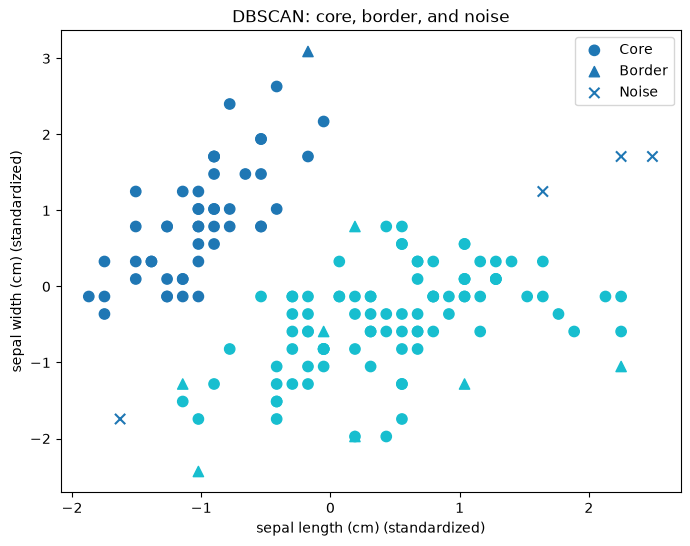

In [28]:
# 1. DBSCAN scatter plot distinguishing core, border, and noise
fig, ax = plt.subplots(figsize=(8, 6))
for point_type, marker in [("Core", "o"), ("Border", "^"), ("Noise", "x")]:
    mask = dbscan_type == point_type
    ax.scatter(
        X[mask, 0], X[mask, 1],
        c=dbscan_labels[mask], cmap="tab10",
        marker=marker, s=55, label=point_type
    )
ax.set_xlabel(feature_names[0] + " (standardized)")
ax.set_ylabel(feature_names[1] + " (standardized)")
ax.set_title("DBSCAN: core, border, and noise")
ax.legend()
plt.show()


The plot distinguishes core, border, and noise observations. Most observations belong to dense regions, while a small number are classified as noise. DBSCAN identifies clusters without requiring predefined cluster centres.

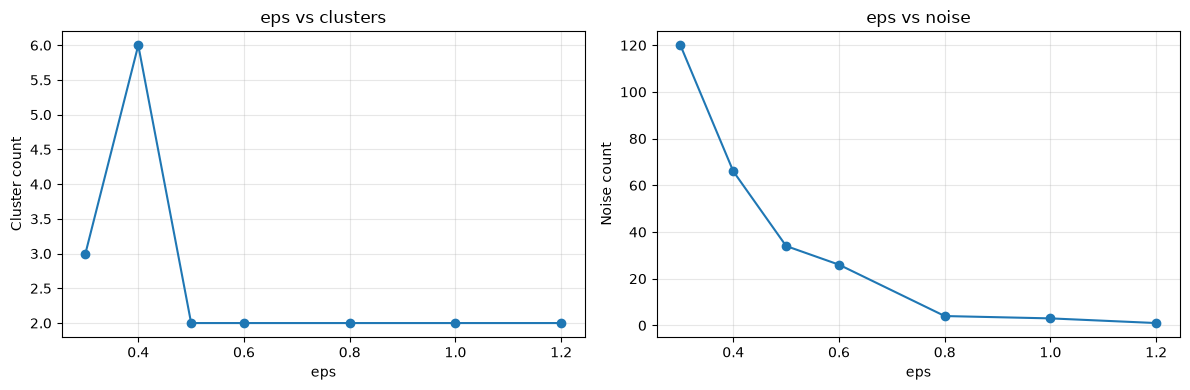

In [29]:

# 2. eps versus cluster count and noise count
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(eps_results["eps"], eps_results["Cluster count"], marker="o")
axes[0].set(xlabel="eps", ylabel="Cluster count", title="eps vs clusters")
axes[1].plot(eps_results["eps"], eps_results["Noise count"], marker="o")
axes[1].set(xlabel="eps", ylabel="Noise count", title="eps vs noise")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


As eps increases, neighbourhoods become larger and more observations become density-reachable. The experiments show a reduction in noise points and a change in cluster count at smaller eps values. At larger eps values, the number of clusters becomes relatively stable.

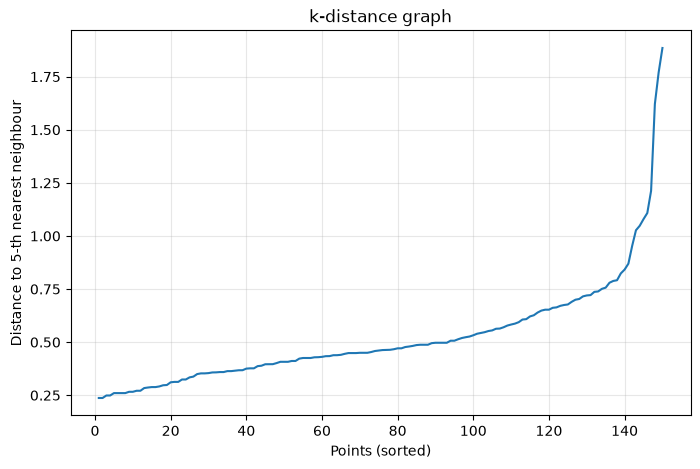

In [30]:

# 3. k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances)
plt.xlabel("Points (sorted)")
plt.ylabel(f"Distance to {K_FOR_DISTANCE}-th nearest neighbour")
plt.title("k-distance graph")
plt.grid(alpha=0.3)
plt.show()


The k-distance graph shows the sorted distances to the fifth nearest neighbour. A region where distances begin increasing more rapidly can indicate a possible elbow and help select eps. The elbow is not always sharply defined, so the selected value should also be validated experimentally.

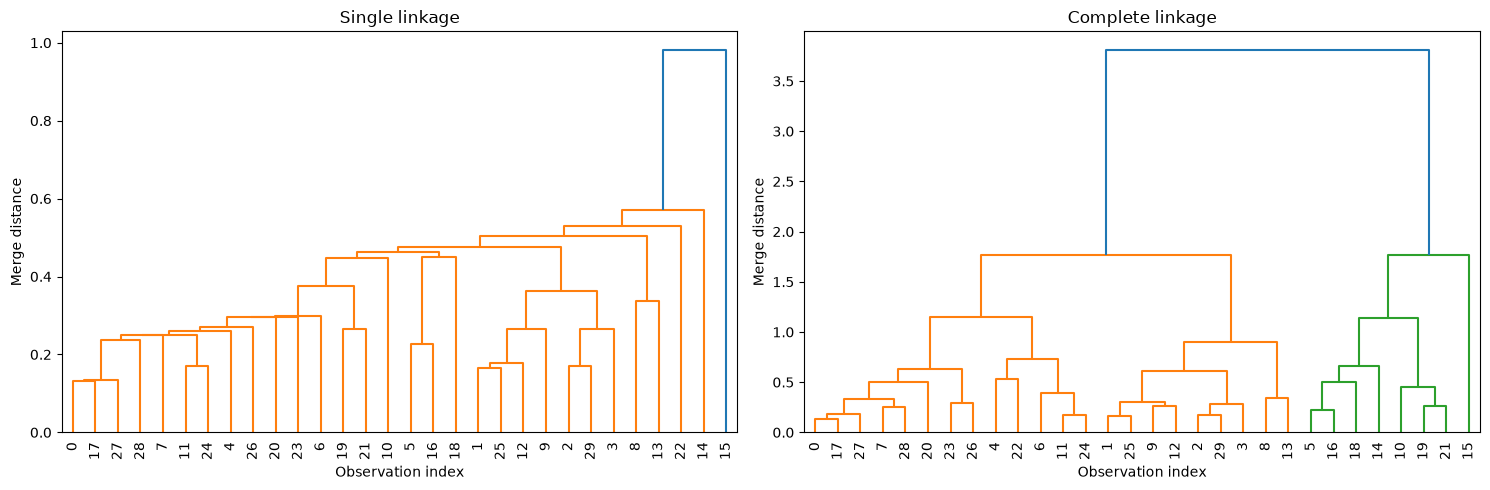

In [31]:

# 4. Dendrograms for two linkage methods on the manageable subset
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, method in zip(axes, ["single", "complete"]):
    _, _, history = agglomerative_clustering(
        X_dendrogram, linkage=method, n_clusters=1
    )
    Z = scipy_linkage_matrix_from_history(history, len(X_dendrogram))
    dendrogram(Z, ax=ax, labels=[str(i) for i in range(len(X_dendrogram))],
               leaf_rotation=90)
    ax.set_title(f"{method.capitalize()} linkage")
    ax.set_xlabel("Observation index")
    ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.show()


The dendrograms illustrate the different merging behaviours of single and complete linkage. Single linkage can produce chaining, whereas complete linkage generally delays merges between clusters whose farthest observations are relatively distant.

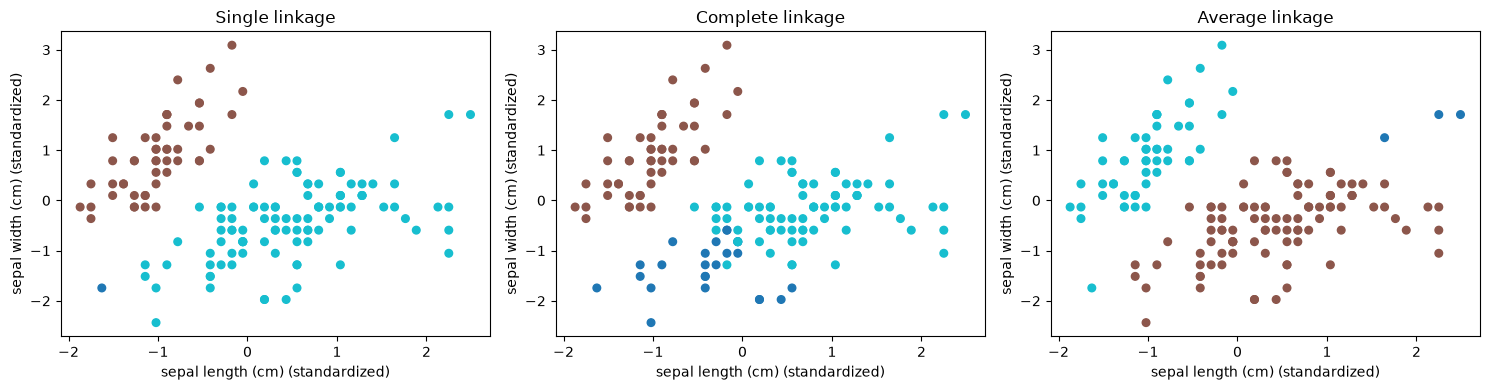

In [32]:

# 5. Hierarchical cluster plots for all three linkage methods
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, method in zip(axes, LINKAGE_METHODS):
    labels = hierarchical_results[method]["labels"]
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=30)
    ax.set_title(f"{method.capitalize()} linkage")
    ax.set_xlabel(feature_names[0] + " (standardized)")
    ax.set_ylabel(feature_names[1] + " (standardized)")
plt.tight_layout()
plt.show()


The three linkage methods produce different cluster memberships. Single linkage exhibits chaining, complete linkage favours more compact groups, and average linkage provides a compromise based on mean pairwise distances.

,Configuration,Silhouette
0,DBSCAN,0.597941
1,Hierarchical-single,0.504646
2,Hierarchical-complete,0.449618
3,Hierarchical-average,0.480267


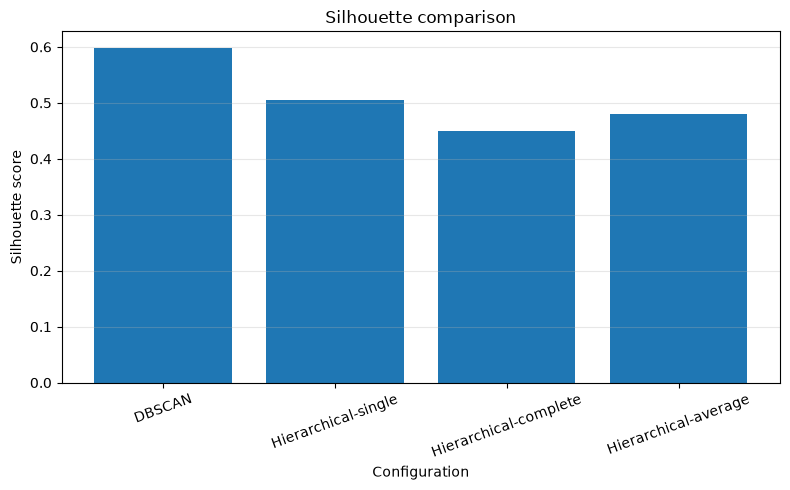

In [33]:

# 6. Compare selected DBSCAN and hierarchical silhouette scores
comparison_silhouette = [
    {
        "Configuration": "DBSCAN",
        "Silhouette": dbscan_silhouette
    }
]
for method in LINKAGE_METHODS:
    labels = hierarchical_results[method]["labels"]
    comparison_silhouette.append({
        "Configuration": f"Hierarchical-{method}",
        "Silhouette": safe_silhouette(X, labels)
    })

comparison_silhouette_df = pd.DataFrame(comparison_silhouette)
display(comparison_silhouette_df)

plt.figure(figsize=(8, 5))
plt.bar(
    comparison_silhouette_df["Configuration"],
    comparison_silhouette_df["Silhouette"]
)
plt.xlabel("Configuration")
plt.ylabel("Silhouette score")
plt.title("Silhouette comparison")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


DBSCAN achieves a silhouette score of approximately 0.598, compared with 0.505 for single linkage, 0.450 for complete linkage, and 0.480 for average linkage. DBSCAN has the highest silhouette score among these selected configurations. However, its score is calculated only on non-noise observations.

### Task 21: Algorithmic Complexity and Practical Observation

A full pairwise distance matrix requires \(O(N^2)\) memory. A straightforward DBSCAN implementation that scans all observations for each neighbourhood query can require \(O(N^2)\) distance work overall; spatial indexing structures can accelerate queries in suitable low-dimensional settings, though their benefit can diminish in high dimensions. Straightforward agglomerative clustering repeatedly searches for the closest cluster pair and updates inter-cluster distances, which can require substantial time and memory as the number of observations grows.

- **DBSCAN:** Advantage — detects irregularly shaped dense regions and identifies noise; limitation — sensitive to global density parameters; suitable for spatial clustering and anomaly detection.
- **Hierarchical clustering:** Advantage — provides a nested hierarchy and supports different linkage criteria; limitation — can be computationally and memory intensive; suitable for biological data analysis and document grouping.

DBSCAN expands clusters by visiting core points and exploring their epsilon-neighbourhoods. It adds density-reachable observations to existing clusters and identifies observations that cannot be assigned as noise.

Agglomerative hierarchical clustering repeatedly finds the closest pair of clusters and merges them according to a linkage criterion. It continues until the stopping condition is reached.

DBSCAN focuses on density connectivity, whereas hierarchical clustering builds a sequence of nested partitions based on inter-cluster distances. DBSCAN can identify noise directly, while hierarchical clustering generally assigns every observation to a cluster.

### Task 22: Final Results Table

In [34]:
# Compact final results table using the measured experiment results
final_results_rows = [
    {
        "Experiment": "DBSCAN main run",
        "Setting": f"eps={EPS_MAIN}, MinPts={MIN_PTS_MAIN}",
        "Result": (
            f"Clusters={dbscan_cluster_count}; noise={len(dbscan_noise)}; "
            f"sizes={dbscan_cluster_sizes.to_dict()}"
        )
    },
    {
        "Experiment": "DBSCAN eps study",
        "Setting": f"eps values={EPS_VALUES}",
        "Result": eps_results[
            ["eps", "Cluster count", "Noise count", "Cluster sizes"]
        ].to_dict("records")
    },
    {
        "Experiment": "DBSCAN MinPts study",
        "Setting": f"MinPts values={MIN_PTS_VALUES}",
        "Result": minpts_results[
            ["MinPts", "Cluster count", "Noise count", "Cluster sizes"]
        ].to_dict("records")
    },
    {
        "Experiment": "Hierarchical",
        "Setting": "Single/complete/average; k=3",
        "Result": hierarchical_rows
    },
    {
        "Experiment": "Linkage and k",
        "Setting": f"k={K_VALUES}",
        "Result": linkage_k_results.to_dict("records")
    },
    {
        "Experiment": "Overall evaluation",
        "Setting": "Selected configurations",
        "Result": evaluation_table.to_dict("records")
    }
]

final_results_table = pd.DataFrame(final_results_rows)
display(final_results_table)


,Experiment,Setting,Result
0,DBSCAN main run,"eps=0.8, MinPts=5","Clusters=2; noise=4; sizes={0: 49, 1: 97}"
1,DBSCAN eps study,"eps values=[0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]","[{'eps': 0.3, 'Cluster count': 3, 'Noise count..."
2,DBSCAN MinPts study,"MinPts values=[3, 4, 5, 6, 8, 10]","[{'MinPts': 3, 'Cluster count': 2, 'Noise coun..."
3,Hierarchical,Single/complete/average; k=3,"[{'Linkage': 'single', 'Cluster sizes': [1, 49..."
4,Linkage and k,"k=[2, 3, 4, 5]","[{'Linkage': 'single', 'k': 2, 'Cluster sizes'..."
5,Overall evaluation,Selected configurations,"[{'Algorithm': 'DBSCAN', 'Parameters': 'eps=0...."


### Task 23: Observations and Conclusion

### Observations

1. DBSCAN with eps = 0.8 and MinPts = 5 produces two clusters containing 49 and 97 observations, with four observations classified as noise.

2. DBSCAN successfully identifies noise observations and does not require the number of clusters to be specified beforehand.

3. Hierarchical clustering produces different cluster memberships depending on the linkage criterion. Single linkage exhibits chaining, while complete linkage produces relatively compact groups.

4. Increasing eps generally reduces the number of noise observations. Increasing MinPts makes the core-point condition stricter and can increase the number of noise observations.

5. The hierarchical experiments show that increasing the number of clusters generally reduces silhouette scores. Single and average linkage achieve their highest silhouette scores at k = 2 in the tested configurations.

6. DBSCAN achieves a silhouette score of approximately 0.598 in the selected configuration, higher than the tested hierarchical configurations with k = 3.

### Parameter Observation

1. Epsilon controls neighbourhood size and strongly influences cluster connectivity. Very small values produce fragmented clusters and excessive noise, while large values can merge distinct groups.

2. MinPts controls the minimum density required to form core points. Higher values impose stricter density requirements and can reject sparse regions.

3. Linkage criteria influence hierarchical cluster formation. Single linkage favours connectivity, complete linkage favours compactness, and average linkage considers the average pairwise distance between clusters. Increasing the distance threshold generally reduces the number of clusters.

### Conclusion



DBSCAN and hierarchical clustering provide two different approaches to unsupervised clustering.

DBSCAN is particularly useful for identifying dense regions, irregularly shaped clusters, and noise observations without requiring the number of clusters in advance. However, its performance depends on selecting suitable eps and MinPts values, especially when clusters have different densities.

Hierarchical clustering provides a nested representation of the dataset and allows different cluster structures to be explored through linkage criteria and dendrogram cuts. However, it can be computationally expensive and does not naturally identify noise.

Feature scaling is important for both methods because their cluster formation depends on distance calculations.

Overall, DBSCAN is suitable for spatial analysis and anomaly detection, while hierarchical clustering is useful for biological data analysis, customer segmentation, and document grouping.